<h1 align="center"> Aplicações em Processamento de Linguagem Natural </h1>
<h3 align="center"> Prof. Fernando Vieira da Silva MSc.</h3>

<h2 align="center"> Trabalho 01</h2>
<h3 align="center"> José Diniz - RA: 183134</h3>

<h3 align="center"> Roberto Rodrigues - RA: 060235</h3>

Um sistema de classificação de tópicos consiste em um modelo capaz de identificar a qual domínio uma determinada sentença ou texto pertence. 

Crie um classificador que receba uma frase em inglês e indique se ela faz parte de uma das seguintes categorias: aventura, ficção científica, religião ou governo, utilizando o corpus em anexo.
Use as etapas de pré-processamento que vimos em sala e representações de texto diferentes se desejar (bag-of-words/LSA, Skip-gram, CBOW, GloVe). 

Utilize os algoritmos de classificação que desejar, e faça seleção de hiperparâmetros. Siga sempre as boas práticas para experimentos de aprendizado de máquina para evitar underfitting e overfitting.

O grupo que obtiver o melhor resultado no corpus de teste (de posse somente do professor) receberá 1 ponto a mais na média de disciplina. Se mais de um grupo tiver o mesmo melhor resultado, nenhum grupo ganhará essa pontuação.

A entrega deve ser feita por meio de script no kaggle compartilhado com o usuário do professor. Basta copiar o link na submissão da solução.

In [69]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import nltk
from nltk.tokenize import sent_tokenize
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
import string
import matplotlib.pyplot as plt

<h3>1. Lendo o data set</h3>

In [70]:
df = pd.read_csv('corpus_categorias_treino.csv')
df.head(10)

,Unnamed: 0,words,category
0,0,He certainly didn't want a wife who was fickle...,adventure
1,1,"If he had married her , he'd have been asking ...",adventure
2,2,Sometimes he woke up in the middle of the nigh...,adventure
3,3,His plans and dreams had revolved around her s...,adventure
4,4,The best antidote for the bitterness and disap...,adventure
5,5,He found that if he was tired enough at night ...,adventure
6,6,Each day he found himself thinking less often ...,adventure
7,7,"each day the hurt was a little duller , a litt...",adventure
8,8,He had plenty of work to do .,adventure
9,9,"The grass in the meadows came fast , now that ...",adventure


In [71]:
df.isna().sum()

Unnamed: 0    0
words         0
category      0
dtype: int64

In [72]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8200 entries, 0 to 8199
Data columns (total 3 columns):
Unnamed: 0    8200 non-null int64
words         8200 non-null object
category      8200 non-null object
dtypes: int64(1), object(2)
memory usage: 192.3+ KB


In [73]:
df.category.unique()

array(['adventure', 'science_fiction', 'religion', 'government'],
      dtype=object)

In [74]:
print(df.words[:10])

0    He certainly didn't want a wife who was fickle...
1    If he had married her , he'd have been asking ...
2    Sometimes he woke up in the middle of the nigh...
3    His plans and dreams had revolved around her s...
4    The best antidote for the bitterness and disap...
5    He found that if he was tired enough at night ...
6    Each day he found himself thinking less often ...
7    each day the hurt was a little duller , a litt...
8                        He had plenty of work to do .
9    The grass in the meadows came fast , now that ...
Name: words, dtype: object


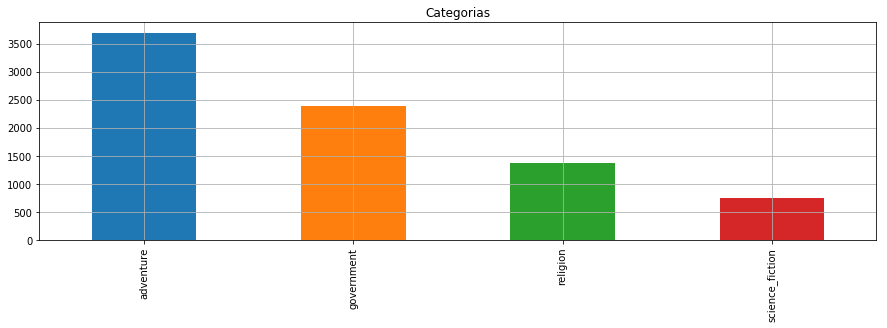

In [75]:
plt.figure(figsize=(15,4))
plt.title('Categorias')
df.category.value_counts().plot(kind='bar');
plt.grid()

<h3>2. Dividindo o dataset em dados de treino e teste</h3>

In [76]:
X = np.array(df.words, dtype=object)
y = np.array(df.category, dtype=object)

In [77]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)

<h3>3. Treinando o classificador</h3>

In [78]:
import nltk
#nltk.download()
from nltk import pos_tag
from nltk.corpus import stopwords
from nltk.corpus import wordnet
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
import string

from sklearn.model_selection import RandomizedSearchCV
from sklearn.model_selection import GridSearchCV

from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, TfidfTransformer
from sklearn.pipeline import Pipeline
from sklearn import neighbors
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score
from sklearn.metrics import log_loss
from sklearn.metrics import f1_score
import scipy

Método utilizado para realizar a tokenização

In [79]:
stopwords_list = stopwords.words('english')

lemmatizer = WordNetLemmatizer()

def my_tokenizer(doc):
    words = word_tokenize(doc)
    
    pos_tags = pos_tag(words)
    
    non_stopwords = [w for w in pos_tags if not w[0].lower() in stopwords_list]
    
    non_punctuation = [w for w in non_stopwords if not w[0] in string.punctuation]
    
    lemmas = []
    for w in non_punctuation:
        if w[1].startswith('J'):
            pos = wordnet.ADJ
        elif w[1].startswith('V'):
            pos = wordnet.VERB
        elif w[1].startswith('N'):
            pos = wordnet.NOUN
        elif w[1].startswith('R'):
            pos = wordnet.ADV
        else:
            pos = wordnet.NOUN
        
        lemmas.append(lemmatizer.lemmatize(w[0], pos))

    return lemmas

Método utilizado para realizar a diminuição das dimensionalidade

In [80]:
from sklearn.decomposition import TruncatedSVD

class SVDDimSelect(object):
    def fit(self, X, y=None):        
        try:
            self.svd_transformer = TruncatedSVD(n_components=round(X.shape[1]/2))
            self.svd_transformer.fit(X)
        
            cummulative_variance = 0.0
            k = 0
            for var in sorted(self.svd_transformer.explained_variance_ratio_)[::-1]:# do maior para o menor
                cummulative_variance += var
                if cummulative_variance >= 0.5:
                    break
                else:
                    k += 1
                
            self.svd_transformer = TruncatedSVD(n_components=k)
        except Exception as ex:
            print(ex)
            
        return self.svd_transformer.fit(X)
    
    def transform(self, X, Y=None):
        return self.svd_transformer.transform(X)
        
    def get_params(self, deep=True):
        return {}

Método utilizado para exibição dos melhores parâmtros

In [81]:
def showBestParameters(hyp_sel, parameters):
    print("Best score: %0.3f" % hyp_sel.best_score_)
    print("Best parameters set:")
    best_parameters = hyp_sel.best_estimator_.get_params()
    for param_name in sorted(parameters.keys()):
        print("\t%s: %r" % (param_name, best_parameters[param_name]))

Método utilizado para exibição dos resultados do modelo

In [82]:
def showResults(model, X_Test, y_Test):
    
    y_pred = model.predict(X_Test)
    y_pred_p = model.predict_proba(X_Test)
    
    print(model)# exibição dos parametros utilizados no modelo
    print('----------------------------------------------------')
    print(classification_report(y_Test, y_pred,target_names=df.category.unique()))
    print('----------------------------------------------------')
    print('Acurácia: {:.4f} %'.format(model.score(X_Test, y_Test) * 100))
    print('Log Loss: {:.4f} '.format(log_loss(y_Test, y_pred_p)))
    print('----------------------------------------------------')

<h2>KNN</h2>

In [15]:
clf_KNN = neighbors.KNeighborsClassifier(n_neighbors=12, weights='distance')#melhores parametros encontrados
pipeline_KNN = Pipeline([('tfidf', TfidfVectorizer(tokenizer=my_tokenizer)),\
                        ('svd', SVDDimSelect()), \
                        ('clf', clf_KNN)])

In [16]:
#par_KNN = {'clf__n_neighbors': range(1, 60), 'clf__weights': ['uniform', 'distance']}
#hyperpar_selector_KNN = RandomizedSearchCV(pipeline_KNN, par_KNN, cv=2, scoring='accuracy', n_jobs=1, n_iter=20)
#hyperpar_selector_KNN.fit(X=X_train, y=y_train)
#showBestParameters(hyperpar_selector_KNN, par_KNN)
#showResults(hyperpar_selector_KNN, X_test, y_test)

In [17]:
pipeline_KNN.fit(X=X_train, y=y_train)

Pipeline(memory=None,
     steps=[('tfidf', TfidfVectorizer(analyzer='word', binary=False, decode_error='strict',
        dtype=<class 'numpy.float64'>, encoding='utf-8', input='content',
        lowercase=True, max_df=1.0, max_features=None, min_df=1,
        ngram_range=(1, 1), norm='l2', preprocessor=None, smooth_idf=True,...',
           metric_params=None, n_jobs=None, n_neighbors=12, p=2,
           weights='distance'))])

In [18]:
showResults(pipeline_KNN, X_test, y_test)

Pipeline(memory=None,
     steps=[('tfidf', TfidfVectorizer(analyzer='word', binary=False, decode_error='strict',
        dtype=<class 'numpy.float64'>, encoding='utf-8', input='content',
        lowercase=True, max_df=1.0, max_features=None, min_df=1,
        ngram_range=(1, 1), norm='l2', preprocessor=None, smooth_idf=True,...',
           metric_params=None, n_jobs=None, n_neighbors=12, p=2,
           weights='distance'))])
----------------------------------------------------
                 precision    recall  f1-score   support

      adventure       0.56      0.81      0.67      1108
science_fiction       0.51      0.55      0.53       717
       religion       0.75      0.13      0.23       412
     government       0.45      0.04      0.07       223

      micro avg       0.55      0.55      0.55      2460
      macro avg       0.57      0.38      0.37      2460
   weighted avg       0.57      0.55      0.50      2460

----------------------------------------------------
Acu

<h2>Regressão Logistica</h2>

In [83]:
clf_LogisticR = LogisticRegression(solver='liblinear',n_jobs=1, C=1e5)
pipeline_LogisticR = Pipeline([('tfidf', TfidfVectorizer(tokenizer=my_tokenizer)),\
                       ('svd', SVDDimSelect()), \
                        ('clf', clf_LogisticR)])

In [20]:
#par_LogisticR= { 'clf__solver': ['liblinear','lbfgs'] }
#hyperpar_selector_LogisticR = GridSearchCV(pipeline_LogisticR, par_LogisticR, cv=2, scoring='accuracy', n_jobs=1)
#hyperpar_selector_LogisticR.fit(X=X_train, y=y_train)
#showBestParameters(hyperpar_selector_LogisticR, par_LogisticR)
#showResults(hyperpar_selector_KNN, X_test, y_test)

In [84]:
pipeline_LogisticR.fit(X=X_train, y=y_train)

Pipeline(memory=None,
     steps=[('tfidf', TfidfVectorizer(analyzer='word', binary=False, decode_error='strict',
        dtype=<class 'numpy.float64'>, encoding='utf-8', input='content',
        lowercase=True, max_df=1.0, max_features=None, min_df=1,
        ngram_range=(1, 1), norm='l2', preprocessor=None, smooth_idf=True,...enalty='l2', random_state=None,
          solver='lbfgs', tol=0.0001, verbose=0, warm_start=False))])

In [85]:
showResults(pipeline_LogisticR, X_test, y_test)

Pipeline(memory=None,
     steps=[('tfidf', TfidfVectorizer(analyzer='word', binary=False, decode_error='strict',
        dtype=<class 'numpy.float64'>, encoding='utf-8', input='content',
        lowercase=True, max_df=1.0, max_features=None, min_df=1,
        ngram_range=(1, 1), norm='l2', preprocessor=None, smooth_idf=True,...enalty='l2', random_state=None,
          solver='lbfgs', tol=0.0001, verbose=0, warm_start=False))])
----------------------------------------------------
                 precision    recall  f1-score   support

      adventure       0.81      0.89      0.85      1108
science_fiction       0.84      0.87      0.85       717
       religion       0.73      0.63      0.68       412
     government       0.50      0.32      0.39       223

      micro avg       0.79      0.79      0.79      2460
      macro avg       0.72      0.68      0.69      2460
   weighted avg       0.78      0.79      0.78      2460

----------------------------------------------------
Acu

# Doc2vec and Logistic Regression

In [40]:
from tqdm import tqdm
tqdm.pandas(desc="progress-bar")
from gensim.models import Doc2Vec
from gensim.models import doc2vec
from sklearn import utils
import gensim
from gensim.models.doc2vec import TaggedDocument
import re

def label_sentences(corpus, label_type):
    """
    Gensim's Doc2Vec implementation requires each document/paragraph to have a label associated with it.
    We do this by using the TaggedDocument method. The format will be "TRAIN_i" or "TEST_i" where "i" is
    a dummy index of the post.
    """
    labeled = []
    for i, v in enumerate(corpus):
        label = label_type + '_' + str(i)
        labeled.append(doc2vec.TaggedDocument(v.split(), [label]))
    return labeled
X_train, X_test, y_train, y_test = train_test_split(df.words, df.category, random_state=0, test_size=0.3)
X_train = label_sentences(X_train, 'Train')
X_test = label_sentences(X_test, 'Test')
all_data = X_train + X_test

In [41]:
all_data[:2]

[TaggedDocument(words=['It', 'made', 'only', 'a', 'tiny', 'bump', 'over', 'the', 'two', 'men', 'like', 'a', 'tire', 'over', 'a', 'piece', 'of', 'gravel', 'then', 'moved', 'on', '.'], tags=['Train_0']),
 TaggedDocument(words=['The', 'objectification', 'of', 'the', 'world', 'of', 'spirit', 'in', 'popular', 'superstition', 'had', 'certainly', 'gone', 'far', 'beyond', 'what', 'the', 'experience', 'of', 'spirit', 'could', 'justify', 'or', 'support', '.'], tags=['Train_1'])]

In [66]:
model_dbow = Doc2Vec(dm=0, vector_size=450, negative=5, min_count=1, alpha=0.065, min_alpha=0.065)
model_dbow.build_vocab([x for x in tqdm(all_data)])

for epoch in range(30):
    model_dbow.train(utils.shuffle([x for x in tqdm(all_data)]), total_examples=len(all_data), epochs=1)
    model_dbow.alpha -= 0.002
    model_dbow.min_alpha = model_dbow.alpha

100%|██████████| 8200/8200 [00:00<00:00, 2051738.52it/s]


In [67]:
import numpy as np
def get_vectors(model, corpus_size, vectors_size, vectors_type):
    """
    Get vectors from trained doc2vec model
    :param doc2vec_model: Trained Doc2Vec model
    :param corpus_size: Size of the data
    :param vectors_size: Size of the embedding vectors
    :param vectors_type: Training or Testing vectors
    :return: list of vectors
    """
    vectors = np.zeros((corpus_size, vectors_size))
    for i in range(0, corpus_size):
        prefix = vectors_type + '_' + str(i)
        vectors[i] = model.docvecs[prefix]
    return vectors
    
train_vectors_dbow = get_vectors(model_dbow, len(X_train), 450, 'Train')
test_vectors_dbow = get_vectors(model_dbow, len(X_test), 450, 'Test')

In [68]:
import datetime as dt
import warnings
warnings.filterwarnings("ignore")

print(dt.datetime.now().strftime("%d-%m-%Y %H:%M:%S"))

categories = df.category.unique()
logreg = LogisticRegression(n_jobs=1, C=1e5)
logreg.fit(train_vectors_dbow, y_train)
logreg = logreg.fit(train_vectors_dbow, y_train)
y_pred = logreg.predict(test_vectors_dbow)
y_pred_ll = logreg.predict_proba(test_vectors_dbow)

print('accuracy: {:.4f} '.format(accuracy_score(y_pred, y_test)))
print(classification_report(y_test, y_pred,target_names=categories))
print('Log Loss: {:.4f} '.format(log_loss(y_test, y_pred_ll)))

print(dt.datetime.now().strftime("%d-%m-%Y %H:%M:%S"))

25-04-2019 22:27:39
accuracy: 0.7817 
                 precision    recall  f1-score   support

      adventure       0.81      0.89      0.85      1106
science_fiction       0.85      0.88      0.86       734
       religion       0.69      0.61      0.65       405
     government       0.32      0.19      0.24       215

      micro avg       0.78      0.78      0.78      2460
      macro avg       0.67      0.64      0.65      2460
   weighted avg       0.76      0.78      0.77      2460

Log Loss: 0.6781 
25-04-2019 22:29:18


<h2>Naive Bayes</h2>

In [23]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfTransformer

clf_NB = MultinomialNB()
pipeline_NB = Pipeline([('vect', CountVectorizer()),\
                       ('tfidf', TfidfTransformer()), \
                        ('clf', clf_NB)])

In [24]:
pipeline_NB.fit(X=X_train, y=y_train)

Pipeline(memory=None,
     steps=[('vect', CountVectorizer(analyzer='word', binary=False, decode_error='strict',
        dtype=<class 'numpy.int64'>, encoding='utf-8', input='content',
        lowercase=True, max_df=1.0, max_features=None, min_df=1,
        ngram_range=(1, 1), preprocessor=None, stop_words=None,
        strip...inear_tf=False, use_idf=True)), ('clf', MultinomialNB(alpha=1.0, class_prior=None, fit_prior=True))])

In [25]:
showResults(pipeline_NB, X_test, y_test)

Pipeline(memory=None,
     steps=[('vect', CountVectorizer(analyzer='word', binary=False, decode_error='strict',
        dtype=<class 'numpy.int64'>, encoding='utf-8', input='content',
        lowercase=True, max_df=1.0, max_features=None, min_df=1,
        ngram_range=(1, 1), preprocessor=None, stop_words=None,
        strip...inear_tf=False, use_idf=True)), ('clf', MultinomialNB(alpha=1.0, class_prior=None, fit_prior=True))])
----------------------------------------------------
                 precision    recall  f1-score   support

      adventure       0.69      0.99      0.81      1108
science_fiction       0.83      0.86      0.84       717
       religion       0.93      0.27      0.42       412
     government       1.00      0.00      0.01       223

      micro avg       0.74      0.74      0.74      2460
      macro avg       0.86      0.53      0.52      2460
   weighted avg       0.80      0.74      0.68      2460

----------------------------------------------------
Acu

<h2>Conclusão</h2>

Como a distribuição das classes se encontram desbalanceadas, as métricas análisadas foram focanas na F1-score (média harmonica entre precisão e o recall).
Concluindo-se que o melhor modelo que apresentou os valores mais altos para F1-score foi o de Regressão Logistica para o modelo de multi-classes.